# 06a: Sequence-Length and Temporal-Structure Investigation

This is one of six notebooks covering the deep-learning (FNN/LSTM/TCN) side of this thesis:

- `06a_sequence_investigation.ipynb` -- jobs-per-user distribution, the sequence-length choice, padding policy, the sequence-construction leakage test, and F-DATA/PM100 lag-1 autocorrelation; also holds the deep-learning feature-set explanation shared by the notebooks below.
- `06b_model_architectures.ipynb` -- the FNN/SequenceLSTM/SequenceTCN/`_CausalConvBlock`/FlatDataset/SequenceDataset class definitions, documented layer by layer, an equivalence check against `src/models.py`, architecture diagrams, the training configuration, and a checkpoint-match check across all 18 (combination, architecture) pairs.
- `06c_dl_power.ipynb` -- the real FNN/LSTM/TCN sweep for F-DATA power and PM100 power.
- `06d_dl_duration.ipynb` -- the same for F-DATA duration and PM100 duration.
- `06e_dl_memory.ipynb` -- the same for F-DATA memory and PM100 memory (`pm100_memory_c4`).
- `06f_dl_comparison.ipynb` -- the F-DATA duration/memory raw-space collapse diagnostic (including the three-user inspection), the same-features classical-ML control, and the six-combination summary against classical ML.

Before any FNN/LSTM/TCN architecture work, four things are established and documented here,
in order -- the same discipline used for the feature-vetting and analytical-baseline work
earlier in this project:

1. A defensible sequence length, from the real jobs-per-user distribution rather than a round
   number chosen by convention.
2. The padding/masking policy for users with less history than that length.
3. An explicit, executed test that the sequence-construction code cannot leak a job's own
   future into its own input -- a different kind of risk than the classical-ML feature-leakage
   checks already done, since sequence construction is new code with a leakage risk of its own.
4. Whether F-DATA's job submissions show any real temporal structure at all: LSTM/TCN's whole
   premise (a user's recent job history predicts their next job) only helps where that
   structure exists, and an earlier working note in this project had assumed, without
   checking it against the data, that F-DATA doesn't have it.

Core sequence-construction logic lives in `src/sequences.py` (reused by the LSTM/TCN training
in notebooks 06c/06d/06e); this notebook runs the actual investigation.

**The DL feature set is not identical to classical ML's (05/05b/05c).** Three column families are dropped for the DL models specifically, scoped to the deep-learning pipeline only -- classical ML's own already-adopted results are untouched:
- Absolute epoch-timestamp columns (`adt_epoch`/`qdt_epoch`/`schedsdt_epoch` for F-DATA, `submit_time_epoch`/`eligible_time_epoch` for PM100) -- standardized on tune_train, a chronologically-later test period's values land several std devs out of range, which a standardized neural net cannot extrapolate through (trees tolerate this fine via boundary splits).
- Per-split `pd.factorize()`-coded categorical columns (`jobenv_req_code` for F-DATA; `partition_code`/`qos_code`/`shared_code`/`group_id_code` for PM100) -- the integer code is order-of-first-appearance WITHIN each split, so the same real category can get a different code in train vs test. Replaced, not just dropped: one-hot encoded instead, fit on the train+test population combined so both splits get identical dummy columns.
- Per-split user-frequency columns (`usr_freq` for F-DATA, `user_id_freq` for PM100) -- same issue class, a user's test-period job count has nothing to do with their train-period count.

See `src/dl_data.py`'s `load_combo` for the real implementation of all three.

In [1]:
import sys
sys.path.append("..")

import glob
import pathlib
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import features, plotting, sequences

pd.set_option("display.width", 160)
FIGURES_DIR = pathlib.Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)


## Jobs-per-user distribution and the sequence-length tradeoff

Computed on the full completed-jobs population for each dataset (not just the test split --
sequence history for a test-set job legitimately reaches back into that user's training-period
jobs). For each candidate sequence length N, two different usability metrics, since they tell
different stories: the fraction of **users** who ever accumulate N jobs (relevant to whether the
model ever sees a full-length example from a given user), and the fraction of **jobs**
(training examples) that get a fully unpadded sequence at that N (relevant to how much of the
actual training signal needs padding).

In [2]:
CANDIDATE_LENGTHS = [5, 10, 20, 50]


def analyze_jobs_per_user(name, df, user_col, time_col):
    df = df[[user_col, time_col]].copy()
    df[time_col] = pd.to_datetime(df[time_col])
    df = df.sort_values([user_col, time_col], kind="mergesort")

    counts = df.groupby(user_col).size()
    n_users = len(counts)
    n_jobs = len(df)
    print(f"{name}: {n_users:,} unique users, {n_jobs:,} jobs "
          f"(mean {n_jobs / n_users:.1f} jobs/user)")
    display(counts.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
            .to_frame("jobs_per_user"))

    position = df.groupby(user_col).cumcount()
    rows = []
    for N in CANDIDATE_LENGTHS:
        users_with_N = int((counts >= N).sum())
        jobs_unpadded = int((position >= N).sum())
        rows.append(dict(seq_len=N, users_with_ge_N_jobs_pct=users_with_N / n_users,
                          jobs_fully_unpadded_pct=jobs_unpadded / n_jobs))
    summary = pd.DataFrame(rows)
    display(summary.style.format({"users_with_ge_N_jobs_pct": "{:.2%}",
                                   "jobs_fully_unpadded_pct": "{:.2%}"}))

    jobs_zero_history = int((position == 0).sum())
    print(f"jobs with ZERO prior history (a user's first job): {jobs_zero_history:,} "
          f"({jobs_zero_history / n_jobs:.2%})")
    return counts, summary


In [3]:
t0 = time.perf_counter()
FDATA_DIR = "../data/raw/fdata"
fdata_files = sorted(glob.glob(f"{FDATA_DIR}/*.parquet"))[:38]
print(f"loading {len(fdata_files)} F-DATA months (no embedding)")
fdata_base = features.load_fdata_no_embedding(fdata_files)
fdata_base = features.filter_completed_jobs(fdata_base, "fdata")
fdata_base = features.handle_mszl_sentinel(fdata_base)
print(f"loaded and filtered in {time.perf_counter() - t0:.0f}s")

fdata_counts, fdata_seqlen_summary = analyze_jobs_per_user("F-DATA", fdata_base, "usr", "adt")


loading 38 F-DATA months (no embedding)


[fdata] excluded 9.9% of jobs as non-completed (2558519 / 25866900)


loaded and filtered in 20s


F-DATA: 3,309 unique users, 23,308,381 jobs (mean 7043.9 jobs/user)


,jobs_per_user
count,3309.000000
mean,7043.935026
std,44384.824350
min,1.000000
10%,2.000000
25%,9.000000
50%,64.000000
75%,508.000000
90%,4311.400000
95%,19190.800000


,seq_len,users_with_ge_N_jobs_pct,jobs_fully_unpadded_pct
0,5,83.20%,99.94%
1,10,73.77%,99.88%
2,20,64.79%,99.78%
3,50,52.98%,99.54%


jobs with ZERO prior history (a user's first job): 3,309 (0.01%)


In [4]:
PM100_PATH = "../data/raw/pm100/pm100_job_table.parquet"
pm100_base = pd.read_parquet(PM100_PATH)
pm100_base = features.filter_completed_jobs(pm100_base, "pm100")

pm100_counts, pm100_seqlen_summary = analyze_jobs_per_user("PM100", pm100_base, "user_id",
                                                             "submit_time")


[pm100] excluded 22.0% of jobs as non-completed (50928 / 231238)
PM100: 427 unique users, 180,310 jobs (mean 422.3 jobs/user)


,jobs_per_user
count,427.000000
mean,422.271663
std,2032.573871
min,1.000000
10%,2.000000
25%,8.000000
50%,40.000000
75%,180.500000
90%,537.200000
95%,1153.900000


,seq_len,users_with_ge_N_jobs_pct,jobs_fully_unpadded_pct
0,5,81.50%,98.95%
1,10,73.07%,98.05%
2,20,62.53%,96.47%
3,50,47.31%,92.73%


jobs with ZERO prior history (a user's first job): 427 (0.24%)


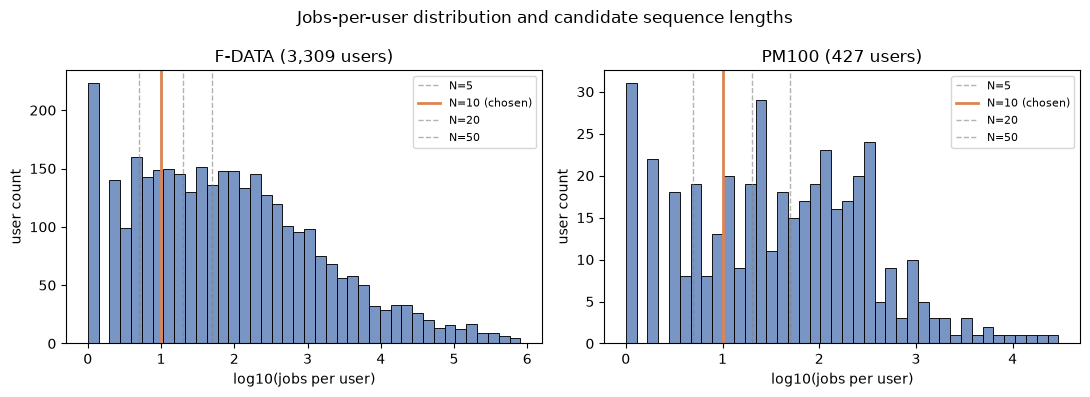

In [5]:
fig = plotting.plot_sequence_length_distribution(
    {"F-DATA": fdata_counts, "PM100": pm100_counts}, CANDIDATE_LENGTHS, sequences.SEQ_LEN
)
fig.savefig(FIGURES_DIR / "notebook06_sequence_length_distribution.png", dpi=150,
            bbox_inches="tight")
plt.show()


Figure above: jobs-per-user distribution for each dataset, with the four candidate sequence lengths marked (N=10, chosen, in solid orange; the rejected candidates dashed grey).

Both distributions are extremely right-skewed: a handful of heavy users contribute the large
majority of jobs (F-DATA: 3,309 users average 7,044 jobs each but the median user has only 64;
PM100: 427 users average 422 jobs each but the median user has only 40). This is why the two
usability metrics diverge so much at large N -- even at N=50, by the same count-based proxy
used throughout this section, over 99.5% (F-DATA) / 92.7% (PM100) of individual **jobs**
still have >= N same-user jobs earlier in sorted order, even though fewer than 53%/47% of
**users** ever accumulate 50 jobs at all.

**Decision: SEQ_LEN = 10.** Meaningfully longer than the classical-ML rolling-mean feature's
own winning window (5, established in notebooks 05/05b) -- giving LSTM/TCN a real chance to
capture something that feature didn't -- while keeping job-level padding losses low by a cheap
COUNT-BASED PROXY (`position >= N` on each user's own sorted job list, used here only because it
is fast enough to sweep across all four candidate lengths: 99.88% F-DATA / 98.05% PM100 "fully
unpadded" at N=10) and still covering a clear majority of users (73.8% / 73.1%) with at least
one full-length sequence somewhere in their history by that same proxy.

**That 99.88%/98.05% is a proxy number, not what the real sequence index gives.** The
mask-based diagnostic later in this notebook (right after the leakage test, once
`build_sequence_index` has actually run) measures the true fraction directly from the real
mask and finds roughly half, not 99%+: about 51% of jobs on both datasets get a fully unpadded
sequence, and 17-19% get an all-padding one. The gap is the same same-timestamp exclusion the
leakage fix itself needed -- `build_sequence_index`'s strict "<" check throws out any candidate
history position that shares the target job's own submit timestamp, which batch/near-simultaneous
submissions make common enough to roughly halve the usable history. **SEQ_LEN = 10 is kept
anyway.** This proxy's only job here is to rank the four CANDIDATE lengths (5/10/20/50) against
each other before the real index exists, and that ranking should be largely unaffected by the
correction (ties remove positions at every candidate length; not separately measured): the
same same-timestamp exclusion applies at every candidate length, so 10 still gives
meaningfully more potential history than the classical rolling-mean window (5) without requiring
the much rarer 50-job history the next candidate up would need. Raising SEQ_LEN would not
recover the positions lost to same-timestamp ties; only a different sequence construction would
(a PM100-only variant that does not exclude same-timestamp predecessors is examined
separately, outside this notebook's original scope).

## Padding/masking policy

**Decision: zero-pad + boolean mask for every job; exclude nobody.** A user with fewer than 10
prior jobs gets left-padded with zero rows and a mask marking those positions as not-real; no
user or job is dropped from the sequence-model dataset. Chosen specifically so LSTM/TCN's row
population is IDENTICAL to FNN's and the classical models' for all six combinations, avoiding a
"different row populations, flag it" caveat on every later comparison table. Jobs with
genuinely zero prior history BY COUNT (a user's very first job -- 0.01% of F-DATA jobs, 0.24% of
PM100's, from the jobs-per-user distribution above) get an all-padding sequence, which the mask
correctly communicates to the model as "no history available" rather than presenting fabricated
zeros as real. **This is not the only source of an all-padding sequence**, though: a job whose
closest same-user predecessors all share its own exact submit timestamp also ends up with every
history slot excluded by the strict-time check, even though it has prior jobs by count -- the
real-sequence verification cell after the leakage test below measures this directly and finds it
affects a much larger share of jobs (roughly one in six on F-DATA, one in five on PM100) than the
literal zero-history-by-count case does. The masking policy still handles this correctly -- an
all-padding sequence from either cause is reported to the model as "no history," not fabricated
history -- but "no history available" is far more common in practice than the zero-prior-jobs-by-
count number alone suggests.

## Sequence construction and the no-leakage test

`src/sequences.build_sequence_index` builds each job's sequence input; `verify_no_leakage` is
an explicit, executed check -- not an assumption -- that every real (non-padding) sequence
position (a) belongs to the same user as its target job, (b) has a strictly earlier timestamp,
and (c) is never the target row itself.

**What a sequence position actually holds**: `build_sequence_index` only returns row INDICES
(and the mask) -- `src/models.SequenceDataset` is what turns an index into the actual input, by
looking up that row's own full Tier A feature vector (the SAME columns every "current job" input
uses, from `src/dl_data.load_combo`'s own output). So each real history position is the prior
job's own SUBMISSION-TIME feature vector -- what it requested, when, as whom -- not that prior
job's measured outcome (its own execution time/memory/power are never in this vector; those are
Tier B and excluded by the Tier A/Tier B split this whole project enforces).

**One exception worth naming explicitly: the per-user rolling-mean feature DOES carry target
information**, deliberately. `{target}_user_rolling_mean` (`src/features.add_user_rolling_stat`,
window=5, the classical-ML feature referenced above) is a rolling average of that SAME TARGET's
own past values, shifted by one job so it only ever uses strictly earlier jobs. It is legitimate
Tier A (known before the job in question runs, and the shift(1) means it never leaks a job's own
outcome into its own row) -- but it means a history position's feature vector is not purely
"submission characteristics with no outcome information": one column in it is a lagged summary
of several real outcomes further back in that user's history. This is the same feature
classical ML already relies on (05/05b/05c); nothing new is introduced for the DL models here.

In [6]:
t0 = time.perf_counter()
fdata_seq_idx, fdata_mask = sequences.build_sequence_index(fdata_base["usr"].to_numpy(),
                                                             fdata_base["adt"])
t_build = time.perf_counter() - t0
n_rows_checked, n_pos_checked = sequences.verify_no_leakage(
    fdata_base["usr"].to_numpy(), fdata_base["adt"], fdata_seq_idx, fdata_mask,
    sample_size=5000, seed=0)
print(f"F-DATA: sequence built for {len(fdata_base):,} rows in {t_build:.1f}s")
print(f"  leakage check PASSED on {n_rows_checked:,} sampled rows "
      f"({n_pos_checked:,} real sequence positions verified, 0 violations)")
print(f"  real-position fill rate: {fdata_mask.mean():.2%} (SEQ_LEN={sequences.SEQ_LEN})")


F-DATA: sequence built for 23,308,381 rows in 171.6s
  leakage check PASSED on 5,000 sampled rows (37,933 real sequence positions verified, 0 violations)
  real-position fill rate: 75.74% (SEQ_LEN=10)


In [7]:
t0 = time.perf_counter()
pm100_seq_idx, pm100_mask = sequences.build_sequence_index(pm100_base["user_id"].to_numpy(),
                                                             pm100_base["submit_time"])
t_build = time.perf_counter() - t0
n_rows_checked, n_pos_checked = sequences.verify_no_leakage(
    pm100_base["user_id"].to_numpy(), pm100_base["submit_time"], pm100_seq_idx, pm100_mask,
    sample_size=5000, seed=0)
print(f"PM100: sequence built for {len(pm100_base):,} rows in {t_build:.1f}s")
print(f"  leakage check PASSED on {n_rows_checked:,} sampled rows "
      f"({n_pos_checked:,} real sequence positions verified, 0 violations)")
print(f"  real-position fill rate: {pm100_mask.mean():.2%} (SEQ_LEN={sequences.SEQ_LEN})")


PM100: sequence built for 180,310 rows in 0.6s
  leakage check PASSED on 5,000 sampled rows (35,793 real sequence positions verified, 0 violations)
  real-position fill rate: 71.58% (SEQ_LEN=10)


## How much of the count-based unpadded estimate survives contact with the real sequence index

The two figures above (99.88% F-DATA / 98.05% PM100 "fully unpadded" at N=10) come from a cheap
count-based proxy (`position >= N` on each user's own sorted job list), used because it is fast
enough to sweep across four candidate lengths. It does not know about
`build_sequence_index`'s own strict-time exclusion, which throws out a candidate position
whenever that candidate shares the target job's own submit timestamp -- a real possibility this
proxy cannot see. This cell checks the proxy against the real, already-built `fdata_mask` /
`pm100_mask` (from the leakage test above) directly.

In [8]:
def diagnose_real_padding(name, df, user_col, time_col, mask, highlight_users=None):
    """Compares the count-based `position >= SEQ_LEN` proxy used above against the REAL,
    already-built sequence mask: the distribution of real (non-padding) positions per job, the
    actual fully-unpadded share, and -- among jobs that DO have >= 1 prior job by count -- how
    often the last slot (position SEQ_LEN - 1, the most recent slot) is still padding, and how
    much of that is explained by the target sharing its most-recent prior job's own timestamp."""
    user_arr = df[user_col].to_numpy()
    time_arr = pd.to_datetime(df[time_col]).to_numpy()
    n = len(user_arr)

    tmp = pd.DataFrame({"user_id": user_arr, "time": time_arr, "orig_row": np.arange(n)})
    tmp_sorted = tmp.sort_values(["user_id", "time"], kind="mergesort").reset_index(drop=True)
    pos_in_user_sorted = tmp_sorted.groupby("user_id", sort=False).cumcount().to_numpy()
    pos_in_user = np.empty(n, dtype=np.int64)
    pos_in_user[tmp_sorted["orig_row"].to_numpy()] = pos_in_user_sorted

    real_per_job = mask.sum(axis=1)
    print(f"\n=== {name} ===")
    print("Real (non-padding) positions per job:")
    display(pd.Series(real_per_job).value_counts().sort_index().to_frame("n_jobs"))

    cumcount_est = (pos_in_user >= sequences.SEQ_LEN).mean()
    actual_fully_unpadded = (real_per_job == sequences.SEQ_LEN).mean()
    actual_all_padding = (real_per_job == 0).mean()
    print(f"Count-based estimate used above (position >= {sequences.SEQ_LEN}): {cumcount_est:.2%}")
    print(f"ACTUAL fully-unpadded, from the real mask (mask.sum == {sequences.SEQ_LEN}): "
          f"{actual_fully_unpadded:.2%}")
    print(f"ACTUAL all-padding, from the real mask (mask.sum == 0): {actual_all_padding:.2%} "
          f"(vs. {(pos_in_user == 0).mean():.2%} with literally zero prior jobs by count)")

    has_prior = pos_in_user >= 1
    last_slot_padding = ~mask[:, sequences.SEQ_LEN - 1]
    among_has_prior = has_prior & last_slot_padding
    print(f"Jobs with >= 1 prior job by count: {has_prior.sum():,} ({has_prior.mean():.2%})")
    print(f"  of those, the LAST slot (position {sequences.SEQ_LEN - 1}) is still padding: "
          f"{among_has_prior.sum():,} ({among_has_prior.sum() / has_prior.sum():.2%} of that group)")

    # The most-recent same-user prior job, by count, is one row back in sorted order. If its
    # timestamp equals the target's own, build_sequence_index's strict "<" check excludes it --
    # that is exactly what should explain every "has a prior job by count, but last slot is
    # still padding" case.
    sorted_pos_of_orig = np.empty(n, dtype=np.int64)
    sorted_pos_of_orig[tmp_sorted["orig_row"].to_numpy()] = np.arange(n)
    prior_sorted_pos = np.clip(sorted_pos_of_orig - 1, 0, None)
    prior_time = tmp_sorted["time"].to_numpy()[prior_sorted_pos]
    is_tie = prior_time == time_arr
    explained_by_tie = among_has_prior & is_tie
    print(f"  of those, explained by a same-timestamp TIE with that most-recent prior job: "
          f"{explained_by_tie.sum():,} / {among_has_prior.sum():,} "
          f"({explained_by_tie.sum() / max(among_has_prior.sum(), 1):.2%})")

    if highlight_users:
        rows = []
        for u in highlight_users:
            m = user_arr == u
            if m.sum() == 0:
                continue
            rows.append(dict(user=u, n_jobs=int(m.sum()),
                              fully_unpadded_pct=(real_per_job[m] == sequences.SEQ_LEN).mean() * 100,
                              last_slot_padding_pct=(~mask[m, sequences.SEQ_LEN - 1]).mean() * 100,
                              mean_real_positions=real_per_job[m].mean()))
        print(f"  per-user breakdown ({name}):")
        display(pd.DataFrame(rows).set_index("user").round(2))
    return real_per_job


_ = diagnose_real_padding("F-DATA", fdata_base, "usr", "adt", fdata_mask,
                           highlight_users=["usr_1794", "usr_1848", "usr_2853"])
_ = diagnose_real_padding("PM100", pm100_base, "user_id", "submit_time", pm100_mask)


=== F-DATA ===
Real (non-padding) positions per job:


,n_jobs
0,3993435
1,31221
2,45294
3,92927
4,188534
5,310187
6,618447
7,1130456
8,1690007
9,3400781


Count-based estimate used above (position >= 10): 99.88%
ACTUAL fully-unpadded, from the real mask (mask.sum == 10): 50.66%
ACTUAL all-padding, from the real mask (mask.sum == 0): 17.13% (vs. 0.01% with literally zero prior jobs by count)
Jobs with >= 1 prior job by count: 23,305,072 (99.99%)
  of those, the LAST slot (position 9) is still padding: 11,475,273 (49.24% of that group)


  of those, explained by a same-timestamp TIE with that most-recent prior job: 11,475,273 / 11,475,273 (100.00%)


  per-user breakdown (F-DATA):


,n_jobs,fully_unpadded_pct,last_slot_padding_pct,mean_real_positions
user,,,,
usr_1794,176802,17.44,82.56,2.30
usr_1848,150712,45.13,54.86,5.80
usr_2853,42138,67.08,32.90,7.49



=== PM100 ===
Real (non-padding) positions per job:


,n_jobs
0,34639
1,2239
2,2375
3,2580
4,2852
5,3686
6,4264
7,5087
8,11340
9,18321


Count-based estimate used above (position >= 10): 98.05%
ACTUAL fully-unpadded, from the real mask (mask.sum == 10): 51.54%
ACTUAL all-padding, from the real mask (mask.sum == 0): 19.21% (vs. 0.24% with literally zero prior jobs by count)
Jobs with >= 1 prior job by count: 179,883 (99.76%)
  of those, the LAST slot (position 9) is still padding: 84,074 (46.74% of that group)


  of those, explained by a same-timestamp TIE with that most-recent prior job: 84,074 / 84,074 (100.00%)


**The gap between the count-based estimate and the real mask-based figure is large, not a rounding nuance.** On F-DATA, the real fully-unpadded share is 50.66% (11,807,092 / 23,308,381 jobs), not 99.88% -- the count-based proxy overstates it by roughly 49 percentage points. PM100 shows the same pattern: 51.54% real vs. 98.05% count-based. The real all-padding share is 17.13% on F-DATA and 19.21% on PM100 -- far above the 0.01%/0.24% that comes from counting only a user's literal first job.

**The explanation is exactly the same-timestamp exclusion, and it is complete, not partial.** Among jobs that have at least one prior job by count, the share whose last slot is still padding is 49.24% (F-DATA) and 46.74% (PM100) -- and every single one of those cases (100.00% on both datasets) is explained by the most-recent same-user prior job sharing the target's own submit timestamp. This is not a bug: it is `build_sequence_index`'s strict "<" check (added specifically to pass the leakage test above) doing exactly what it is supposed to do. Batch or near-simultaneous submissions -- not a rare edge case -- are common enough on both datasets that roughly half of all non-first jobs lose their single most recent history slot to a tie, and a job whose nearby predecessors are ALL same-timestamp ties can lose every slot, which is why the all-padding share (17-19%) is so much higher than the literal-first-job share (well under 1%).

**The three F-DATA duration/memory collapse users (`06f_dl_comparison.ipynb`) sit at very different points on this spectrum, and it lines up with how badly their own predictions collapsed.** `usr_1794` -- the user whose rows dominate LSTM/TCN's worst errors -- gets a fully unpadded sequence only 17.44% of the time and loses its last slot to a tie 82.56% of the time, averaging just 2.30 real (of 10) history positions per job: its LSTM/TCN input is mostly padding. `usr_1848` sits in the middle (45.13% fully unpadded, mean 5.80 real positions). `usr_2853` is the least affected of the three (67.08% fully unpadded, mean 7.49 real positions). The user with the thinnest real history is the one whose collapse was most severe.

**A real bug was found and fixed while building this, not just an assumption verified.** The
first implementation of `build_sequence_index` used only sorted-array position (the k-th most
recent same-user row by sort order) to decide what counts as "prior" -- and failed its own
leakage test immediately: some same-user jobs share an **identical submit timestamp** (evidently
batch or near-simultaneous submissions), so a stable sort's tiebreak order is not a valid proxy
for "strictly before." `src/sequences.py` as it stands above already includes the fix (an
explicit strict-time comparison on top of the position check, so a same-timestamp row is
correctly excluded from counting as a prior position -- that slot becomes padding instead of
silently-wrong "history"), and both datasets now pass clean, with zero violations on a 5,000-row
sample each.

## F-DATA temporal-structure check (PM100 shown alongside for comparison)

Lag-1 same-user target autocorrelation: for each user, sort their jobs chronologically and
correlate each job's target value with the immediately preceding job's target value from the
same user, pooled across all users. A per-user median is also reported as a robustness check
against a handful of heavy users dominating the pooled number -- the same concern notebook 08
raised about top-heavy user concentration.

In [9]:
def lag1_autocorr(name, user_ids, times, y, return_pairs=False):
    df = pd.DataFrame({"user_id": np.asarray(user_ids), "time": pd.to_datetime(times),
                        "y": np.asarray(y, dtype=float)})
    df = df.sort_values(["user_id", "time"], kind="mergesort")
    df["y_lag1"] = df.groupby("user_id", sort=False)["y"].shift(1)
    paired = df.dropna(subset=["y_lag1"])
    pooled_r = float(np.corrcoef(paired["y"], paired["y_lag1"])[0, 1])
    with np.errstate(invalid="ignore"):  # a handful of users have zero-variance y in this
        # window (e.g. every job identical) -- corrcoef correctly returns NaN for those,
        # dropped below, not a computation error
        per_user_r = paired.groupby("user_id").apply(
            lambda g: np.corrcoef(g["y"], g["y_lag1"])[0, 1] if len(g) >= 10 else np.nan,
            include_groups=False)
    per_user_r = per_user_r.dropna()
    summary = dict(combination=name, n_consecutive_pairs=len(paired), pooled_lag1_r=pooled_r,
                    median_per_user_lag1_r=float(per_user_r.median()),
                    n_users_with_r=len(per_user_r))
    if return_pairs:
        return summary, paired["y"].to_numpy(), paired["y_lag1"].to_numpy()
    return summary


In [10]:
autocorr_rows = []
fdata_pairs_for_plot = {}  # target label -> (y, y_lag1), for the scatter figure below

fdata_power = features.sanitize_fdata_power(fdata_base.copy())
fdata_power = fdata_power.dropna(subset=["avgpcon"])
summary, y, y_lag1 = lag1_autocorr("F-DATA power (avgpcon)", fdata_power["usr"],
                                    fdata_power["adt"], fdata_power["avgpcon"],
                                    return_pairs=True)
autocorr_rows.append(summary)
fdata_pairs_for_plot["F-DATA power (avgpcon)"] = (y, y_lag1)
del fdata_power

summary, y, y_lag1 = lag1_autocorr("F-DATA duration", fdata_base["usr"], fdata_base["adt"],
                                    fdata_base["duration"], return_pairs=True)
autocorr_rows.append(summary)
fdata_pairs_for_plot["F-DATA duration"] = (y, y_lag1)

fdata_memory = features.resolve_fdata_memory_target(fdata_base.copy())
summary, y, y_lag1 = lag1_autocorr("F-DATA memory (mmszu_resolved)", fdata_memory["usr"],
                                    fdata_memory["adt"], fdata_memory["mmszu_resolved"],
                                    return_pairs=True)
autocorr_rows.append(summary)
fdata_pairs_for_plot["F-DATA memory (mmszu_resolved)"] = (y, y_lag1)
del fdata_memory

pm100_base["power_mean"] = pm100_base["node_power_consumption"].apply(np.mean)
autocorr_rows.append(lag1_autocorr("PM100 power (power_mean)", pm100_base["user_id"],
                                    pm100_base["submit_time"], pm100_base["power_mean"]))
autocorr_rows.append(lag1_autocorr("PM100 duration (run_time)", pm100_base["user_id"],
                                    pm100_base["submit_time"], pm100_base["run_time"]))
autocorr_rows.append(lag1_autocorr("PM100 memory (mem_alloc)", pm100_base["user_id"],
                                    pm100_base["submit_time"], pm100_base["mem_alloc"]))

autocorr_df = pd.DataFrame(autocorr_rows).set_index("combination")
display(autocorr_df.style.format({"n_consecutive_pairs": "{:,}", "pooled_lag1_r": "{:.4f}",
                                   "median_per_user_lag1_r": "{:.4f}"}))


,n_consecutive_pairs,pooled_lag1_r,median_per_user_lag1_r,n_users_with_r
combination,,,,
F-DATA power (avgpcon),"23,305,071",0.7542,0.6019,2395
F-DATA duration,"23,305,072",0.9279,0.5326,2393
F-DATA memory (mmszu_resolved),"23,305,072",0.8710,0.6608,2395
PM100 power (power_mean),"179,883",0.8050,0.4338,308
PM100 duration (run_time),"179,883",0.8508,0.4232,308
PM100 memory (mem_alloc),"179,883",0.7908,0.5735,254


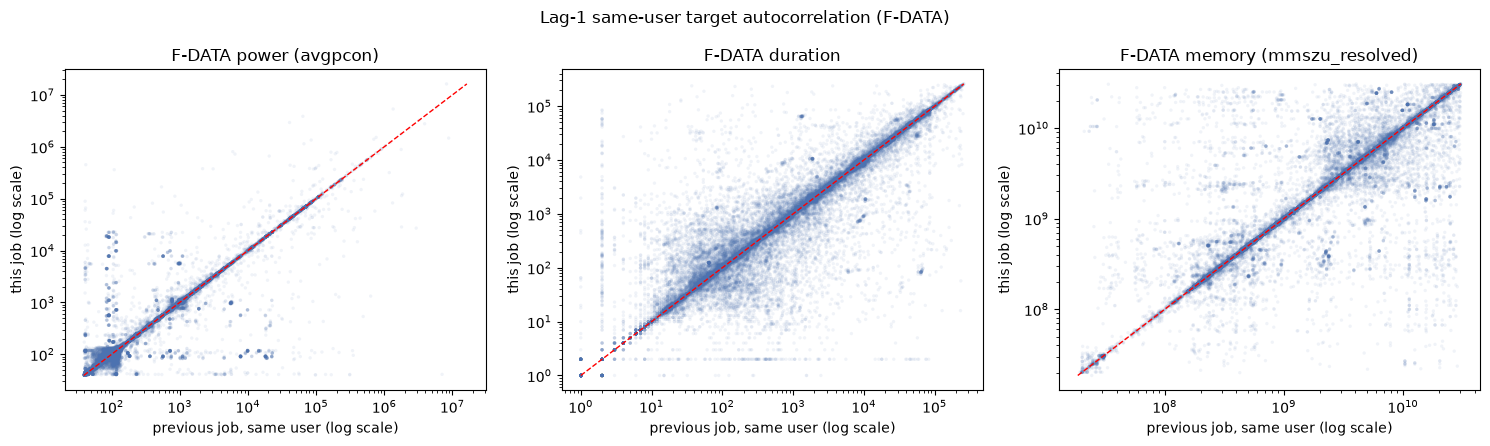

In [11]:
SCATTER_SAMPLE = 50_000  # per panel, for a renderable scatter -- correlation itself (above)
# was computed on the full population, this sample is for the figure only

rng = np.random.default_rng(0)
panels = {}
for title, (y, y_lag1) in fdata_pairs_for_plot.items():
    n = len(y)
    idx = rng.choice(n, size=min(SCATTER_SAMPLE, n), replace=False)
    panels[title] = (y[idx], y_lag1[idx])

fig = plotting.plot_lag1_autocorrelation(panels)
fig.savefig(FIGURES_DIR / "notebook06_fdata_lag1_autocorrelation.png", dpi=150,
            bbox_inches="tight")
plt.show()


Figure above: this job's target vs. the immediately preceding same-user job's target, log-log scale, for F-DATA's three targets (50,000-pair sample per panel; the correlation itself, above, used the full population). The visible diagonal clustering is the same strong autocorrelation the table above reports as a number.

**F-DATA shows strong same-user temporal structure on all three targets** -- pooled r ranges
0.75-0.93, comparable to or exceeding PM100's own autocorrelation on the same targets (e.g.
F-DATA duration's pooled r=0.928 exceeds PM100 duration's 0.851). This directly refutes this
project's own prior, untested assumption that F-DATA had nothing genuinely sequential for an
LSTM/TCN to use -- F-DATA users evidently resubmit jobs with materially
similar execution-time/power/memory footprints in succession, likely repeated or
parameter-swept job families rather than independent one-off submissions.

This does not guarantee LSTM/TCN will beat FNN on F-DATA -- the rolling-mean feature already in
the classical-ML feature set captures some of this same same-user signal -- but it means running
sequence models on F-DATA (rather than assuming it's pointless and skipping it) is justified by
direct evidence, not just methodological even-handedness.

## Sequence-length and temporal-structure investigation: summary

| Question | Decision / finding |
|---|---|
| Sequence length | 10 |
| Padding/masking policy | Zero-pad + mask every job, exclude nobody |
| Leakage check | PASSED on both datasets, after finding and fixing a real same-timestamp-tie issue |
| Real (mask-based) padding at SEQ_LEN=10 | ~51% of jobs fully unpadded, ~17-19% fully padding -- both very different from the cheap count-based proxy used for the sequence-length choice above (99.88%/98.05%), and fully explained by the same same-timestamp exclusion the leakage fix needed |
| F-DATA temporal structure | Strong (pooled lag-1 r = 0.75-0.93 across all three targets); an earlier working note's assumption that nothing is sequential there does not hold |

Notebook 06b (model architectures) and notebooks 06c/06d/06e (the full sweep) follow, now that this investigation is complete.